# Lab 10-07 · BJT Single-Stage Amplifiers

Companion to [chapter 10-07](../../chapters/10-07-bjt-single-stage-amplifiers.md). Predict first; the `assert` lines check against the answer keys.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
VT = 1.380649e-23 * 300 / 1.602176634e-19

def par(*r):
    return 1 / sum(1 / x for x in r)

# Example 10-07.1 bias, solved once (constant-V_BE model, beta = 100), then held fixed
vth, rth = 12 * 10 / 57, par(47e3, 10e3)
IC = (vth - 0.7) / (1e3 + rth / 101) * 100 / 101
GM = IC / VT

## Part 1 · β sweep (guided exercise)

*Predict first:* does the bypassed amplifier's overall gain rise or fall from β = 100 to 300?

r_pi(300) = 6.0292 kOhm; R_in 1.6159 -> 3.4827 kOhm; input factor 0.7769; gain -98.27 -> -123.60 (25.77%)


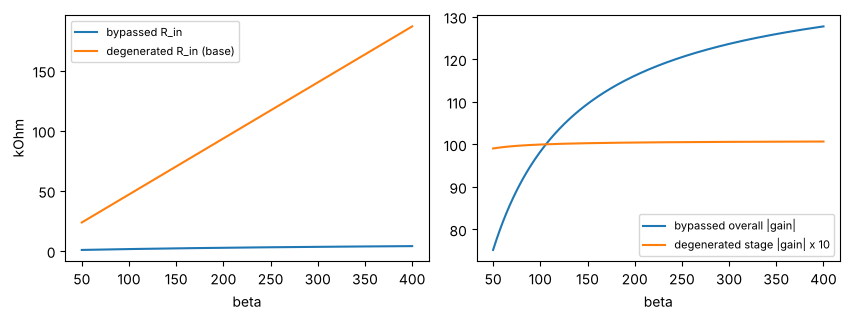

In [2]:
def bypassed(beta):
    rin = par(rth, beta / GM)
    return rin, rin / (rin + 1e3) * (-GM * par(4.7e3, 10e3))

def degenerated(beta, re1=440.0):
    a = beta / (beta + 1); re = a / (1e-3 / VT)
    rin_b = (beta + 1) * (re + re1)
    return rin_b, -a * 4.7e3 / (re + re1)

r100, g100 = bypassed(100); r300, g300 = bypassed(300)
print(f"r_pi(300) = {300/GM/1e3:.4f} kOhm; R_in {r100/1e3:.4f} -> {r300/1e3:.4f} kOhm; "
      f"input factor {r300/(r300+1e3):.4f}; gain {g100:.2f} -> {g300:.2f} ({(g300/g100-1)*100:.2f}%)")
assert abs(300 / GM / 1e3 - 6.029) < 5e-4 and abs(r300 / 1e3 - 3.483) < 5e-4
assert abs(r300 / (r300 + 1e3) - 0.7769) < 5e-5 and abs((g300 / g100 - 1) * 100 - 25.8) < 0.05
betas = np.linspace(50, 400, 200)
fig, (a, b) = plt.subplots(1, 2, figsize=(8.6, 3.3))
a.plot(betas, [bypassed(x)[0] / 1e3 for x in betas], label="bypassed R_in")
a.plot(betas, [degenerated(x)[0] / 1e3 for x in betas], label="degenerated R_in (base)")
a.set_xlabel("beta"); a.set_ylabel("kOhm"); a.legend(fontsize=8)
b.plot(betas, [abs(bypassed(x)[1]) for x in betas], label="bypassed overall |gain|")
b.plot(betas, [abs(degenerated(x)[1]) * 10 for x in betas], label="degenerated stage |gain| x 10")
b.set_xlabel("beta"); b.legend(fontsize=8); fig.tight_layout(); plt.show()

## Part 2 · The output-resistance ceiling

A test source at the collector of a transistor at 1 mA (β = 100, $r_o$ = 50 kΩ), base grounded, solved as a 2-node circuit.

ceiling 5.0526 MOhm; 90% reached at R_E = 23.011 kOhm (8.9 r_pi)


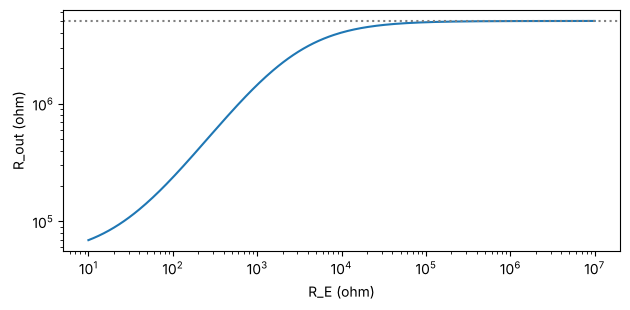

In [3]:
gm, rpi, ro = 1e-3 / VT, 100 / (1e-3 / VT), 50e3

def rout(re):
    # unknowns: emitter voltage v_e and test current i_x with v_x = 1
    # KCL at emitter: i_x = v_e/re + v_e/rpi ; collector: i_x = gm(-v_e) + (1 - v_e)/ro
    a = np.array([[1 / re + 1 / rpi, -1.0], [gm + 1 / ro, 1.0]])
    v_e, i_x = np.linalg.solve(a, [0.0, 1 / ro])
    return 1 / i_x

ceiling = 101 * ro + rpi
r90 = brentq(lambda r: rout(r) - 0.9 * ceiling, 1, 1e8)
print(f"ceiling {ceiling/1e6:.4f} MOhm; 90% reached at R_E = {r90/1e3:.3f} kOhm ({r90/rpi:.1f} r_pi)")
assert abs(r90 / 1e3 - 23.01) < 5e-3
res = np.logspace(1, 7, 300)
plt.figure(figsize=(6.4, 3.2)); plt.loglog(res, [rout(r) for r in res]); plt.axhline(ceiling, ls=":", color="0.5")
plt.xlabel("R_E (ohm)"); plt.ylabel("R_out (ohm)"); plt.tight_layout(); plt.show()

## Part 3 · Follower clipping into a coupled load

Example 10-07.5's follower: $I_E$ = 1.0101 mA through $R_E$ = 5 kΩ, 1 kΩ coupled load. With an exponential transistor, the emitter current $i_E = I_S'e^{(v_B - v_E)/V_T}$ must equal the current into $R_E \parallel R_L$ about the bias point; we find the base amplitude at which the minimum emitter current reaches 1% of its bias value.

negative swing limit I_E (R_E || R_L) = 0.8418 V; reached (to 99%) at a base amplitude of 0.952 V


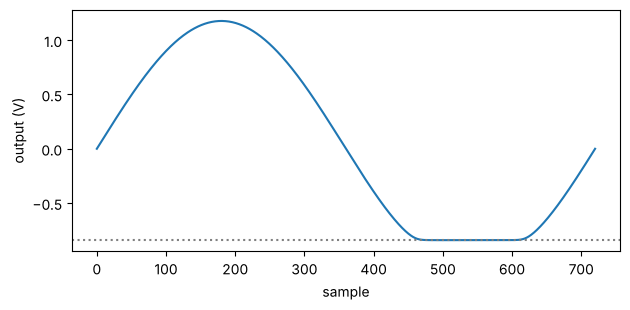

In [4]:
IE0, RE, RL = 1.0101010101e-3, 5e3, 1e3
rp = par(RE, RL)

def emitter_wave(vb_amp, n=721):
    th = np.linspace(0, 2 * np.pi, n)
    out = []
    for t in th:
        vb = vb_amp * math.sin(t)
        # incremental emitter voltage u: IE0*exp((vb - u)/VT) = IE0 + u/rp  (load seen through the coupling capacitor)
        f = lambda u: IE0 * math.exp((vb - u) / VT) - IE0 - u / rp
        out.append(brentq(f, -IE0 * rp - 1e-9, abs(vb) + 1.0, xtol=1e-15))
    return np.array(out)

limit = IE0 * rp
amp = brentq(lambda a: emitter_wave(a).min() + 0.99 * limit, 0.1, 2.0)
print(f"negative swing limit I_E (R_E || R_L) = {limit:.4f} V; reached (to 99%) at a base amplitude of {amp:.3f} V")
assert abs(limit - 0.842) < 5e-4
w = emitter_wave(1.2)
plt.figure(figsize=(6.4, 3.2)); plt.plot(w); plt.axhline(-limit, ls=":", color="0.5")
plt.ylabel("output (V)"); plt.xlabel("sample"); plt.tight_layout(); plt.show()

## Part 4 · MOS against BJT across current

g_m ratio (BJT/MOS at V_ov = 0.2 V): 3.8682 to 3.8682


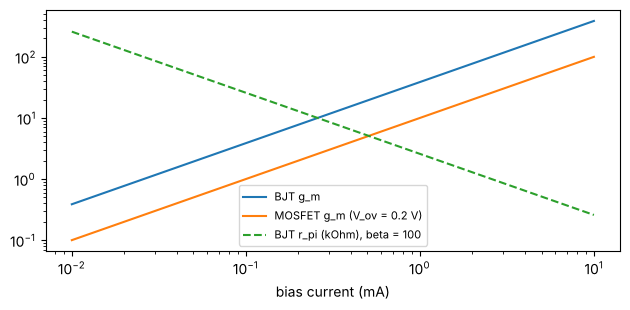

In [5]:
currents = np.logspace(-5, -2, 100)
gm_b = currents / VT; gm_m = 2 * currents / 0.2
ratio = gm_b / gm_m
print(f"g_m ratio (BJT/MOS at V_ov = 0.2 V): {ratio.min():.4f} to {ratio.max():.4f}")
assert abs(ratio.mean() - 3.868) < 5e-4 and np.ptp(ratio) < 1e-12
fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.loglog(currents * 1e3, gm_b * 1e3, label="BJT g_m"); ax.loglog(currents * 1e3, gm_m * 1e3, label="MOSFET g_m (V_ov = 0.2 V)")
ax.loglog(currents * 1e3, 100 / gm_b / 1e3, "--", label="BJT r_pi (kOhm), beta = 100")
ax.set_xlabel("bias current (mA)"); ax.legend(fontsize=8); fig.tight_layout(); plt.show()